In [1]:
from math import floor, ceil, sqrt, pi, sin, cos
import matplotlib.pyplot as plt

In [16]:
# Make list for all solutions for each number of squares
solutions = {i: {'n_squares': i,
                 'box_size': (s:=ceil(sqrt(i))),
                 'method': ('BASE' if (z:=s**2-i)>2 
                            else f'SQUARE-{z}'.strip('-0')), 
                 'score': s/sqrt(i)-1 if i else 0}
             for i in range(1,1001)}

In [ ]:

# best = [{'n_squares': i,
#          'box_size': (s:=ceil(sqrt(i))),
#          'method': 'BASE' if i else 'IGNORE', 
#          'score': s/sqrt(i)-1 if i else 0}
#         for i in range(1001)]

# Mark unimprovable solutions - square, square-1, square-2
for i in range(1001):
    if best[i]['method']=='BASE' and sqrt(i)%1==0:
        best[i]['method'] = 'SQUARE'
    elif best[i]['method']=='BASE' and sqrt(i+1)%1==0:
        best[i]['method'] = 'SQUARE-1'
    elif best[i]['method']=='BASE' and sqrt(i+2)%1==0:
        best[i]['method'] = 'SQUARE-2'
        
# Capture base scores
scores_base = [i['score'] for i in best[1:]]
sum(scores_base)

In [3]:
# Patterns with a rectangle of squares at 45° in the middle
oppdict = dict(zip((z:=['nw', 'ne', 'se', 'sw', 'nw', 'ne']),z[2:]))
sign = lambda x: (x > 0) - (x < 0)

# Loop over combinations of center shape dimensions
for nw_side in range(1,44):
    for ne_side in range(1,nw_side+1):
        # Rows in outside corners
        combos = [{'nw':nw,'se':se,'ne':ne,'sw':sw}
                  for nw in[f(nw_side/sqrt(2)) for f in[floor,ceil]]
                  for se in[f(nw_side/sqrt(2)) for f in[floor,ceil]]
                  for ne in[f(ne_side/sqrt(2)) for f in[floor,ceil]]
                  for sw in[f(ne_side/sqrt(2)) for f in[floor,ceil]]
                  if nw>=se>=ne>=sw]
        for c in combos:
            # Get N squares for this scenario - stop if >1000 or # corner squares prevent solution
            n_squares = nw_side * ne_side + sum([i*(i+1)//2 for i in c.values()])
            if (n_squares > 1000 
                or max([sum([c[j] for j in c if i in j]) 
                        for i in 'nsew']) >= ceil(sqrt(n_squares))):
                continue
            # Calculate smallest bounding box size, required positioning of middle square
            lims = {i: ([nw_side,ne_side][i in['nw','se']]/2)
                    +(((c[i]+1)*sqrt(2)/2) if c[i] else 0.5) 
                    for i in c}
            coords_raw = {i: [[1,-1][j in i]*sqrt((lims[i]**2)/2) 
                              for j in 'nw'] 
                          for i in lims}
            s = (['nw','se'] if (lims['nw']+lims['se'])/sum(lims.values()) >= 0.5 
                 else ['ne','sw'])
            coords_adj = {i:[[coords_raw[k][j] for k in coords_raw if i[j] in k and k in s][0]
                             for j in [0,1]]
                          for i in coords_raw}
            box_size = coords_adj['sw'][0]-coords_adj['nw'][0]
            
            # Test base solution, plus additional solutions made by adding full rows to base solution
            side_sq = {i:sum([c[j] for j in c if i in j]) for i in 'nsew'}
            exp_sides = [[*i][side_sq[i[1]]>side_sq[i[0]]] for i in ['ns','we']]
            exp_inc = sum([side_sq[i] for i in exp_sides])+1
            exp_rows = 0
            while n_squares < 1000:
                # If solution improves on existing base for N squares, update best dict
                if box_size < best[n_squares]['box_size']:
                    best[n_squares]['box_size'] = box_size
                    best[n_squares]['method'] = f"45DEG{'-EXP' if exp_rows else ''}"
                    center_pt = [(box_size-exp_rows-sum([k[i] for k in coords_raw.values()])) / 2 
                                 + (j in exp_sides)*exp_rows
                                 for i,j in enumerate('nw')]
                    best[n_squares]['params'] = {'nw_side': nw_side, 
                                                 'ne_side': ne_side,
                                                 'corner_sq': c, 
                                                 'exp': {i:exp_rows for i in exp_sides}, 
                                                 'center_pt': center_pt}
                    best[n_squares]['score'] = box_size/sqrt(n_squares)-1
                n_squares += exp_inc
                box_size += 1
                exp_inc += 2
                exp_rows += 1
            
        print(f"\rChecked ({nw_side}*{ne_side})", end='')

Checked (43*43)

In [4]:
# Capture updated scores
scores_after_m1 = [i['score'] for i in best[1:]]
sum(scores_after_m1)

23.26114068295558

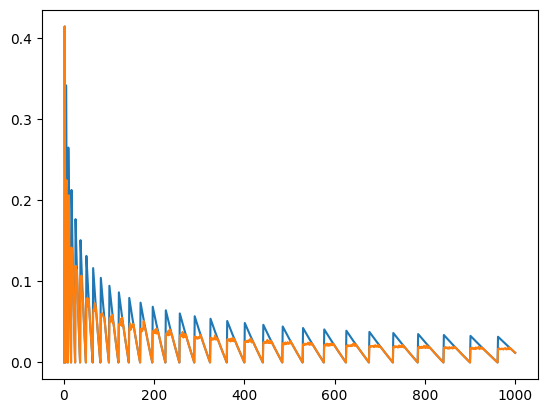

In [5]:
# Scores before and after
sqnum = [i['n_squares'] for i in best[1:]]
plt.plot(sqnum, scores_base)
plt.plot(sqnum, scores_after_m1)
plt.show()

In [7]:
def get_squares(sqdict):
    """
    Get square positioning info (y/x/angle) for specified solution.
    """
    k = sqdict['method']
    return {
        '45DEG': get_squares_45deg, 
        '45DEG-EXP': get_squares_45deg, 
        'BASE': get_squares_base, 
        'SQUARE': get_squares_base, 
        'SQUARE-1': get_squares_base, 
        'SQUARE-2': get_squares_base, 
    }[k](sqdict)
    
def get_squares_base(sqdict):
    """
    Generate square positioning info (y/x/angle) for base solution.
    Methods: 'BASE', 'SQUARE', 'SQUARE-1', 'SQUARE-2'
    """
    return [[i//sqdict['box_size']+0.5, i%sqdict['box_size']+0.5, 0.] 
            for i in range(sqdict['n_squares'])]

def get_squares_45deg(sqdict):
    """
    Generate square positioning info (y/x/angle) for solution based on a 
    central rectangle of squares rotated 45-degrees.
    Methods: '45DEG', '45DEG-EXP'
    """
    squares = []
    expdict = {i: sqdict['params'].get('exp',{}).get(i,0) for i in 'nswe'}
    cy,cx = sqdict['params']['center_pt']
    ne = sqdict['params']['ne_side']
    nw = sqdict['params']['nw_side']

    for c,nrows in sqdict['params']['corner_sq'].items():
        squares += [[y+yy+expdict[c[0]]+0.5 if c[0]=='n' 
                     else sqdict['box_size']-(y+yy+expdict[c[0]]+0.5),
                     x+xx+expdict[c[1]]+0.5 if c[1]=='w' 
                     else sqdict['box_size']-(x+xx+expdict[c[1]]+0.5),
                     0.]
                    for y in range(nrows)
                    for yy in range(0 if y else -expdict[c[0]], 1)
                    for x in range(nrows-y)
                    for xx in range(0 if x else -expdict[c[1]], 1)]

    squares += [[cy+((i-(ne-1)/2)*cos(pi/4))-((j-(nw-1)/2)*sin(pi/4)),
                 cx+((i-(ne-1)/2)*sin(pi/4))+((j-(nw-1)/2)*cos(pi/4)),
                 pi/4]
                for i in range(ne)
                for j in range(nw)]
    return sorted(add_micro_spacing(squares, sqdict['box_size']))

def add_micro_spacing(squares, box_size, e=1e-12):
    """
    Add tiny spaces between squares, avoid disqualification due to rounding.
    """
    d = {}
    for i in [0,1]:
        dsq = [0, *sorted({j[i] for j in squares}), box_size]
        d[i] = {j: j + j/dsq[-1]*e for j in dsq}
    return [[d[0][i[0]], d[1][i[1]], i[2]] for i in squares]

def show_squares(squares):
    plt.subplots()[1].set_aspect('equal', adjustable='box')
    for i in squares:
        edges = [[x*sin(i[2])+y*cos(i[2])+i[0],
                  x*cos(i[2])-y*sin(i[2])+i[1]] 
                 for y,x in [[-0.5,-0.5],[-0.5,0.5],[0.5,0.5],[0.5,-0.5],[-0.5,-0.5]]]
        plt.plot(*zip(*edges), color='black')
    plt.show()

In [12]:
import pandas as pd

submission = (pd.DataFrame([[i['n_squares'], sqnum, sq[1], sq[0], sq[2]]
                            for i in best[1:]
                            for sqnum,sq in enumerate(get_squares(i))],
                           columns=['n', 'square_id', 'x', 'y', 'angle'])
              .reset_index(names='id'))
submission.to_csv('../data/submission.csv', sep=',', index=False)

In [17]:
best[85]

{'n_squares': 85,
 'box_size': 9.778174593052023,
 'method': '45DEG',
 'score': 0.06059194555076375,
 'params': {'nw_side': 11,
  'ne_side': 1,
  'corner_sq': {'nw': 8, 'se': 8, 'ne': 1, 'sw': 1},
  'exp': {'n': 0, 'w': 0},
  'center_pt': [4.889087296526012, 4.889087296526012]}}

85 9.778174593052023


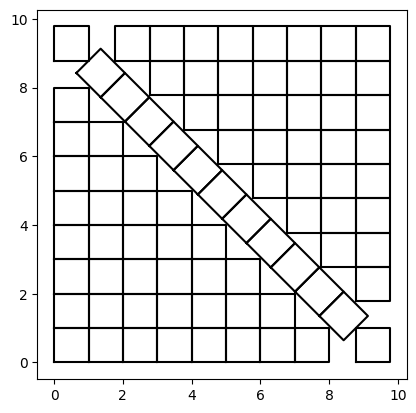

In [18]:
for i in best[85:][:1]:
    print(i['n_squares'], i['box_size'])
    show_squares(get_squares(i))
    print()